# Симуляция A/B-теста: сортировка отзывов по предсказанной информативности

**Контекст.** На карточке товара пользователю показывают 5 отзывов из 20 доступных. Сейчас (контроль, **A**) порядок не связан с содержанием отзыва (например, по дате). Предлагается (тест, **B**) показывать 5 отзывов с наибольшей информативностью по предсказанию лучшей модели из `informativeness.ipynb` (символьные n-граммы + Gradient Boosting).

**Гипотеза.** H0: доля отзывов, отмеченных «полезно», в A и B одинакова. H1: в B она выше.

**Метрика.** Доля показанных отзывов, отмеченных пользователем как полезные (усредняется по пользователям; единица рандомизации — пользователь).

**Допущения симуляции** (реальных логов поведения в датасете нет):
- пользователь отмечает отзыв полезным с вероятностью, равной его **истинной** информативности из разметки;
- в эксперименте используются только отзывы, **не попавшие** в обучающую выборку модели (458 433 − 30 000);
- α = 0.05, мощность 0.8, минимальный детектируемый эффект (MDE) — +1 п.п.

План: оценка дисперсии метрики → расчёт размера групп → A/A-тест (проверка корректности схемы) → A/B-тест → выводы.

In [1]:
import re, joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, nltk
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

seed = 42
rng = np.random.default_rng(seed)
try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')
russian_stopwords = nltk.corpus.stopwords.words('russian')

# Та же предобработка, что в informativeness.ipynb (блок 2) — модель обучалась на ней
def preprocess_text(text):
    if pd.isna(text) or not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'\d{4,}', ' YEAR ', text)
    text = re.sub(r'\d{1,3}(?:[.,]\d+)?\s*(?:gb|гб|tb|тб|mp|мп|ghz|ггц|nm|нм|inch|дюйм)', ' TECH_SPEC ', text)
    text = re.sub(r'\b\d+\b', ' NUM ', text)
    text = re.sub(r'\d+\s*(?:руб|рублей|р\.)', ' MONEY ', text)
    text = re.sub(r'[^\w\sа-яё]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    words = []
    for w in text.split():
        if len(w) <= 1:
            continue
        if w in ['NUM', 'YEAR', 'TECH_SPEC', 'MONEY']:
            words.append(w)
        elif w not in russian_stopwords and len(w) > 2:
            words.append(w)
    return ' '.join(words)

## 1. Пул отзывов, которых модель не видела

In [2]:
df = pd.read_csv('informativeness.csv')
# Повторяем отбор из informativeness.ipynb и берём всё, что НЕ попало в 30 000
_, unseen = train_test_split(df, train_size=30000, stratify=df['informativeness'].round(2), random_state=seed)
pool = unseen.sample(n=40000, random_state=seed).reset_index(drop=True)
pool['clean'] = pool['review'].apply(preprocess_text)
pool = pool[pool['clean'].str.len() > 10].reset_index(drop=True)

model = joblib.load('results/best_model.pkl')
pool['pred'] = model.predict(pool['clean'].values)
true_inf, pred_inf = pool['informativeness'].values, pool['pred'].values
print(f'Пул: {len(pool):,} отзывов вне обучающей выборки')
print(f'Качество модели на пуле: R² = {r2_score(true_inf, pred_inf):.3f}, MAE = {mean_absolute_error(true_inf, pred_inf):.3f}')

Пул: 39,517 отзывов вне обучающей выборки
Качество модели на пуле: R² = 0.876, MAE = 0.087


## 2. Модель эксперимента

In [3]:
N_CANDIDATES, N_SHOWN = 20, 5

def simulate(n_users, variant, rng):
    """Доля отзывов, отмеченных «полезно», для каждого пользователя."""
    idx = rng.integers(0, len(pool), size=(n_users, N_CANDIDATES))
    if variant == 'B':  # топ-5 по предсказанию модели
        order = np.argsort(-pred_inf[idx], axis=1)[:, :N_SHOWN]
        shown = np.take_along_axis(idx, order, axis=1)
    else:               # контроль: порядок не зависит от содержания
        shown = idx[:, :N_SHOWN]
    clicks = rng.random(shown.shape) < true_inf[shown]
    return clicks.mean(axis=1)

## 3. Размер выборки

Дисперсию метрики оцениваем на «пилотной» выборке контроля, размер групп — по формуле для двухвыборочного t-теста:

$n = \dfrac{2\,(z_{1-\alpha/2} + z_{1-\beta})^2\,\sigma^2}{\text{MDE}^2}$

In [4]:
ALPHA, POWER, MDE = 0.05, 0.8, 0.01
pilot = simulate(20000, 'A', rng)
sigma = pilot.std(ddof=1)
z = stats.norm.ppf(1 - ALPHA / 2) + stats.norm.ppf(POWER)
N = int(np.ceil(2 * z**2 * sigma**2 / MDE**2))
print(f'Базовое значение метрики: {pilot.mean():.4f}, σ = {sigma:.4f}')
print(f'Нужно пользователей на группу: {N:,} (MDE = +{MDE*100:.0f} п.п.)')

Базовое значение метрики: 0.4092, σ = 0.2211
Нужно пользователей на группу: 7,674 (MDE = +1 п.п.)


## 4. A/A-тест

Две группы контроля, 10 000 повторов. Если схема корректна, доля ложных срабатываний ≈ α, а p-value распределены равномерно.

Доля ложноположительных: 0.0507 (ожидается 0.05; биномиальный тест p = 0.748)
KS-тест на равномерность p-value: p = 0.598


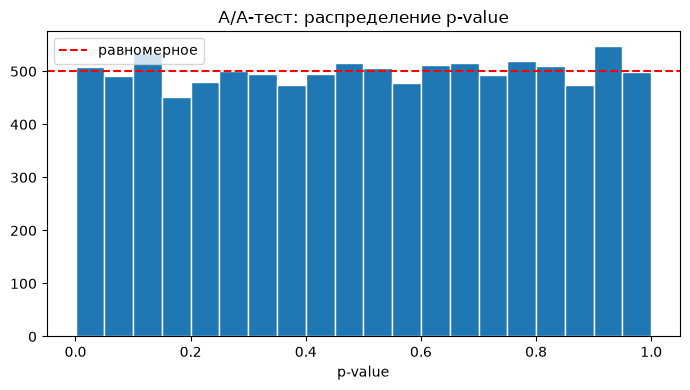

In [5]:
p_aa = np.array([stats.ttest_ind(simulate(N, 'A', rng), simulate(N, 'A', rng), equal_var=False).pvalue
                 for _ in range(10000)])
fpr = (p_aa < ALPHA).mean()
ks_p = stats.kstest(p_aa, 'uniform').pvalue
binom_p = stats.binomtest(int((p_aa < ALPHA).sum()), len(p_aa), ALPHA).pvalue
print(f'Доля ложноположительных: {fpr:.4f} (ожидается {ALPHA}; биномиальный тест p = {binom_p:.3f})')
print(f'KS-тест на равномерность p-value: p = {ks_p:.3f}')
assert binom_p > 0.01, 'A/A-тест не проходит — схема эксперимента некорректна'

plt.figure(figsize=(7, 4))
plt.hist(p_aa, bins=20, edgecolor='white')
plt.axhline(len(p_aa) / 20, color='red', ls='--', label='равномерное')
plt.title('A/A-тест: распределение p-value'); plt.xlabel('p-value'); plt.legend()
plt.tight_layout(); plt.savefig('results/ab_aa_pvalues.png', dpi=120); plt.show()

## 5. A/B-тест

A (контроль): 0.4072   B (тест): 0.8321   n = 7,674 на группу
Абсолютный эффект: +42.50 п.п., 95% ДИ [41.87; 43.12] п.п.
Bootstrap 95% ДИ: [41.87; 43.09] п.п.
Относительный uplift: +104.4%
Welch t-test (односторонний): t = 133.13, p = 0.00e+00


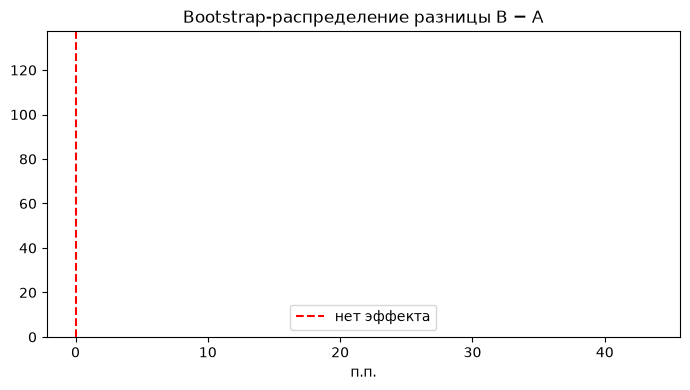

In [6]:
a, b = simulate(N, 'A', rng), simulate(N, 'B', rng)
diff = b.mean() - a.mean()
se = np.sqrt(a.var(ddof=1) / N + b.var(ddof=1) / N)
t_res = stats.ttest_ind(b, a, equal_var=False, alternative='greater')
ci = (diff - 1.96 * se, diff + 1.96 * se)

# Bootstrap-интервал как проверка, не опирающаяся на нормальность
boot = np.array([rng.choice(b, N).mean() - rng.choice(a, N).mean() for _ in range(2000)])
boot_ci = np.percentile(boot, [2.5, 97.5])

print(f'A (контроль): {a.mean():.4f}   B (тест): {b.mean():.4f}   n = {N:,} на группу')
print(f'Абсолютный эффект: {diff*100:+.2f} п.п., 95% ДИ [{ci[0]*100:.2f}; {ci[1]*100:.2f}] п.п.')
print(f'Bootstrap 95% ДИ: [{boot_ci[0]*100:.2f}; {boot_ci[1]*100:.2f}] п.п.')
print(f'Относительный uplift: {diff / a.mean() * 100:+.1f}%')
print(f'Welch t-test (односторонний): t = {t_res.statistic:.2f}, p = {t_res.pvalue:.2e}')

plt.figure(figsize=(7, 4))
plt.hist(boot * 100, bins=40, edgecolor='white')
plt.axvline(0, color='red', ls='--', label='нет эффекта')
plt.title('Bootstrap-распределение разницы B − A'); plt.xlabel('п.п.'); plt.legend()
plt.tight_layout(); plt.savefig('results/ab_bootstrap_diff.png', dpi=120); plt.show()

## 6. Выводы

In [7]:
decision = 'отвергаем H0 — внедряем сортировку по модели' if t_res.pvalue < ALPHA else 'не отвергаем H0'
print(f'При α = {ALPHA}: {decision}.')
print(f'Ожидаемый эффект: {diff*100:+.1f} п.п. к доле полезных отзывов ({diff / a.mean() * 100:+.0f}% относительно контроля).')
print('Ограничение: поведение пользователей смоделировано (P(«полезно») = истинной информативности); '
      'перед внедрением эффект нужно подтвердить онлайн-экспериментом на реальных пользователях.')

При α = 0.05: отвергаем H0 — внедряем сортировку по модели.
Ожидаемый эффект: +42.5 п.п. к доле полезных отзывов (+104% относительно контроля).
Ограничение: поведение пользователей смоделировано (P(«полезно») = истинной информативности); перед внедрением эффект нужно подтвердить онлайн-экспериментом на реальных пользователях.
